In [1]:
import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'
import json
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
import anndata as ad
import seaborn as sns
import geopandas as gpd
from PIL import Image
from spatialdata_io import visium_hd, geojson
from spatialdata.models import TableModel,ShapesModel
from spatialdata_io._constants._constants import VisiumHDKeys
from spatialdata.transformations.transformations import Identity
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context

import warnings
warnings.filterwarnings("ignore")

plt.style.use('default')
plt.rcParams['figure.facecolor'] = 'white'
# os.environ['OPENBLAS_NUM_THREADS'] = '16'
sc.settings.set_figure_params(dpi=80, dpi_save=150, figsize=(5, 5), facecolor='white')

/mnt/NexData_file/home/wyt/software/minicoda/envs/sopa/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/mnt/NexData_file/home/wyt/software/minicoda/envs/sopa/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/mnt/NexData_file/home/wyt/software/minicoda/envs/sopa/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
data_dir = "/home/hf/VH2604022693-01"
sample_info = '/home/hf/VH2604022693-01/sample_info.txt'
output_dir = '/home/hf/VH2604022693-01/OUT/'

if not os.path.exists(output_dir):
    os.makedirs(os.path.join(output_dir, 'data'), exist_ok=True)
    os.makedirs(os.path.join(output_dir, 'report'), exist_ok=True)

for i in ['01-Data_QC', 
          '02-Cell_filter', 
          '03-Dimension_reduction_cluster', 
          '04-Marker_gene_analysis', 
          '05-Cell_type_annotation', 
          '06-Computation_spatial_statistics',
          '07-Cell_Neighborhood_analysis',
          '08-Proximity_analysis'
          ]:
    os.makedirs(os.path.join(output_dir, 'report', i), exist_ok=True)

In [7]:
def read_visiumhd_segmented(data_dir, sample_info, bin_size=8, boundary='cell_segmentations'):
    sample2group = {}
    with open(sample_info, 'r') as f:
        barcodes = pd.DataFrame()   
        for line in f.readlines():
            line = line.strip().split('\t')
            if len(line) > 1:
                sample2group[line[0]] = line[1]
                if len(line) == 3 and '.csv' in line[2]: 
                    sample = line[0]
                    group = line[1]
                    for i in line[2].split(','):
                        tmp = pd.read_csv(f'{i}', skiprows=1, names=['Barcode', 'sample'])
                        barcodes = pd.concat([barcodes,tmp], axis=0, ignore_index=True)
                else:
                    print('sample.txt need two columns')
    
    adata_list = []
    for sample in os.listdir(data_dir):
        if sample in sample2group.keys():
            sdata = visium_hd(
                path=os.path.join(data_dir, sample, 'outs'),
                dataset_id=sample,
                filtered_counts_file=True,
                var_names_make_unique=True,
                bin_size=bin_size
            )
            with open(os.path.join(data_dir, sample, 'outs/segmented_outputs/spatial/scalefactors_json.json')) as file:
                scalefactors = json.load(file)
            # Estimate spot diameter
            hires_img = np.asarray(Image.open(os.path.join(data_dir, sample, 'outs/segmented_outputs/spatial/tissue_hires_image.png')))
            lowres_img = np.asarray(Image.open(os.path.join(data_dir, sample, 'outs/segmented_outputs/spatial/tissue_lowres_image.png')))
            shapes = geojson(os.path.join(data_dir, sample, "outs/segmented_outputs/cell_segmentations.geojson"), coordinate_system=sample)
            areas = shapes.geometry.area
            mean_area = np.mean(areas)
            diameter_pixels = 2 * np.sqrt(mean_area / np.pi)
            scalefactors["spot_diameter_fullres"] = diameter_pixels
            uns_spatial = {
                    sample: {
                        "images": {
                            "hires": hires_img,
                            "lowres": lowres_img,
                        },
                        "scalefactors": scalefactors
                    }
                }

            if boundary=='cell_segmentations' and os.path.exists(os.path.join(data_dir, sample, "outs/segmented_outputs")):
                # add segmentated scRNA data
                adata = sc.read_10x_h5(os.path.join(data_dir, sample, "outs/segmented_outputs/filtered_feature_cell_matrix.h5"), gex_only=False)
                adata.var_names_make_unique()
                adata.obs['sample'] = sample
                adata.obs['group'] = sample2group[sample]
                shapes_name = "cell_segmentation"
                adata.obs[VisiumHDKeys.INSTANCE_KEY] = adata.obs.index.str.replace('cellid_', '').str.replace('-1','').astype(int)
                adata.obs[VisiumHDKeys.REGION_KEY] = shapes_name
                adata.obs[VisiumHDKeys.REGION_KEY] = adata.obs[VisiumHDKeys.REGION_KEY].astype("category")
                adata = TableModel.parse(
                    adata=adata,
                    region=shapes_name,
                    region_key=str(VisiumHDKeys.REGION_KEY),
                    instance_key=str(VisiumHDKeys.INSTANCE_KEY)
                )
                sdata.tables['cells'] = adata.copy()

                # add cell_segmentation boundary
                gdf_seg = gpd.read_file(os.path.join(data_dir, sample, f'outs/segmented_outputs/{boundary}.geojson'))
                gdf_seg.rename(columns={'cell_id':'location_id'}, inplace=True)
                gdf_seg = gdf_seg[gdf_seg['location_id'].isin(adata.obs['location_id'])]
                gdf_seg.set_index('location_id', inplace=True)
                sdata.shapes['cell_segmentation'] = ShapesModel.parse(gdf_seg, transformations={sample: Identity()})

                # add spatial_coords into adata.obsm['spatial]
                gdf = sdata.shapes['cell_segmentation']
                gdf.crs = None
                spatial_coords = np.column_stack([
                    gdf.centroid.x.values, 
                    gdf.centroid.y.values
                ])
                sdata.tables['cells'].obsm['spatial'] = spatial_coords.copy()

                # add cell area in adata.obs, cell area unit is um2
                gdf_seg['cell_area'] = gdf_seg.area * scalefactors['microns_per_pixel'] * scalefactors['microns_per_pixel']
                sdata.tables['cells'].obs = pd.merge(sdata.tables['cells'].obs, gdf_seg['cell_area'], on='location_id', how='inner')

                sdata.tables['cells'].uns["spatial"] = uns_spatial
                adata_list.append(sdata.tables['cells'])
            else:
                tb_name = list(sdata.tables.keys())[0]
                tmp_adata = sdata.tables[tb_name]
                tmp_adata.obs['sample'] = sample
                tmp_adata.obs['group'] = sample2group[sample]
                tmp_adata.var_names_make_unique()

                tmp_adata.uns["spatial"] = uns_spatial
                adata_list.append(tmp_adata)

    adata = ad.concat(adata_list, join='inner', merge='same', uns_merge='first', index_unique=None)
    adata.obs.reset_index(inplace=True, drop=True)
    adata.obs.index = adata.obs.index.astype(str)
    return adata,barcodes

In [8]:
adata,barcodes = read_visiumhd_segmented(
    data_dir=data_dir, 
    sample_info='/home/hf/VH2604022693-01/sample_info.txt', 
    bin_size=8,
    boundary='cell_segmentations'
)

#adata.write(os.path.join(output_dir, 'adata_raw.h5ad'))


#adata

sample.txt need two columns
sample.txt need two columns


In [9]:
adata.obs

,sample,group,location_id,region,cell_area
0,VH2604022693-01_WT1,Control,6,cell_segmentation,52.048406
1,VH2604022693-01_WT1,Control,16,cell_segmentation,76.033738
2,VH2604022693-01_WT1,Control,17,cell_segmentation,31.948074
3,VH2604022693-01_WT1,Control,21,cell_segmentation,32.020317
4,VH2604022693-01_WT1,Control,28,cell_segmentation,48.066888
...,...,...,...,...,...
1399357,VH2604022693-01_WT2,Treatment,270446,cell_segmentation,80.072169
1399358,VH2604022693-01_WT2,Treatment,270448,cell_segmentation,119.843274
1399359,VH2604022693-01_WT2,Treatment,270449,cell_segmentation,159.999432
1399360,VH2604022693-01_WT2,Treatment,270450,cell_segmentation,91.979573


In [10]:
adata.write(os.path.join(output_dir, 'adata_raw.h5ad'))

AnnData object with n_obs × n_vars = 1370304 × 19059
    obs: 'sample', 'group', 'location_id', 'region', 'cell_area'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial', 'spatialdata_attrs'
    obsm: 'spatial'

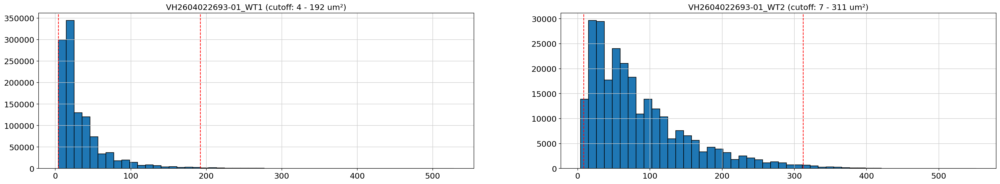

In [12]:
adata = sc.read_h5ad(os.path.join(output_dir, 'adata_raw.h5ad'))

fig, axs = plt.subplots(1, 2, figsize=(30, 5))
axs = axs.flatten()
adata_list = []
for i, s in enumerate(adata.obs['sample'].drop_duplicates()):
    tmp = adata[adata.obs['sample']==s]
    min_cell_area = tmp.obs['cell_area'].quantile(0.01)
    max_cell_area = tmp.obs['cell_area'].quantile(0.99)
    axs[i].hist(tmp.obs['cell_area'], bins=50, edgecolor='black')
    axs[i].axvline(min_cell_area, color='red', linestyle='--', linewidth=1.2)
    axs[i].axvline(max_cell_area, color='red', linestyle='--', linewidth=1.2)
    axs[i].set_title(f'{s} (cutoff: {int(min_cell_area)} - {int(max_cell_area)} um²)')
    tmp = tmp[(tmp.obs['cell_area'] > min_cell_area) & (tmp.obs['cell_area'] < max_cell_area)]
    adata_list.append(tmp)

adata = ad.concat(adata_list, join='inner', merge='same', uns_merge='same', index_unique=None)
adata.write(os.path.join(output_dir, 'adata_cell_area_filter.h5ad'))

adata

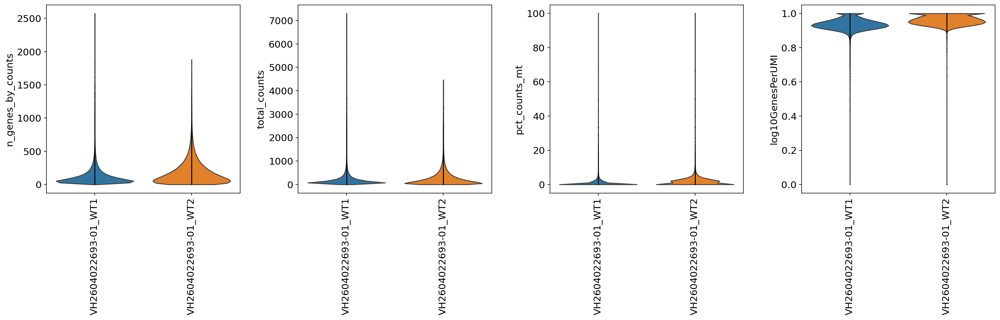

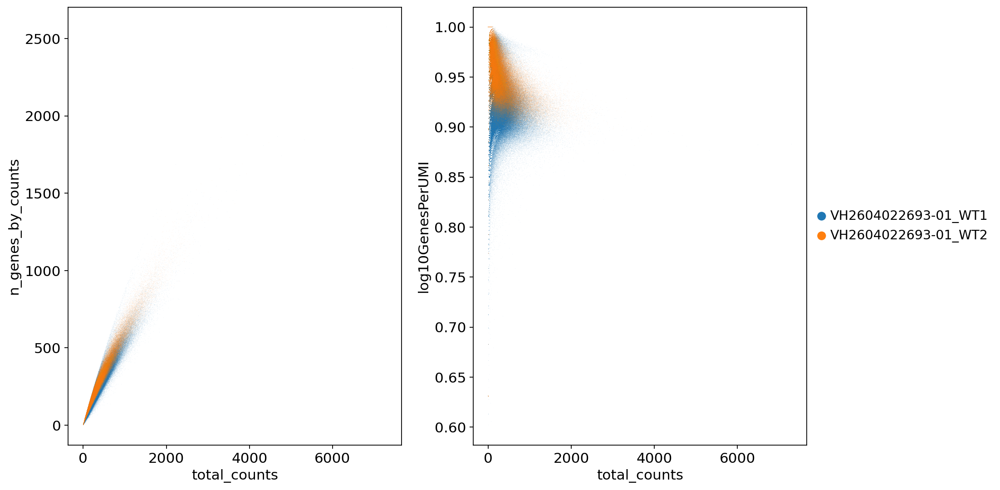

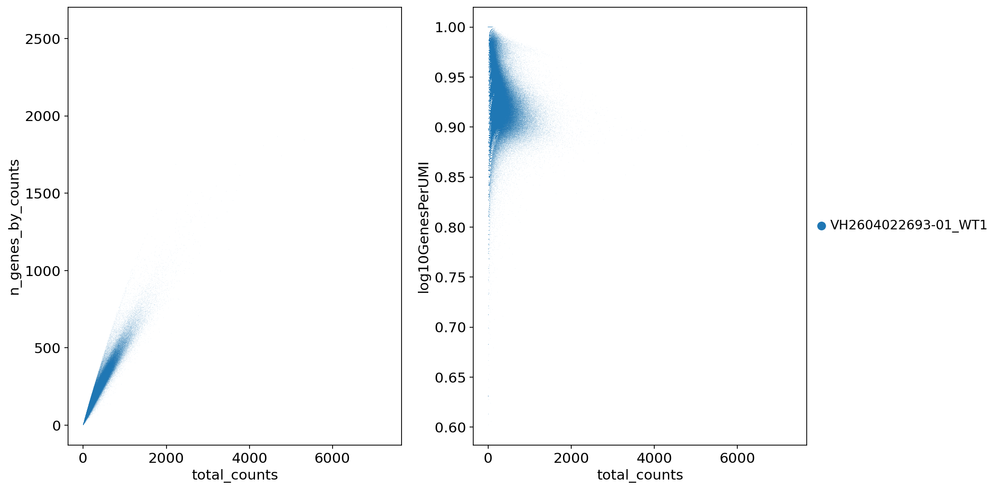

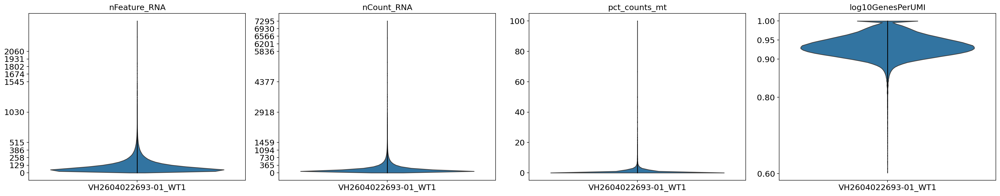

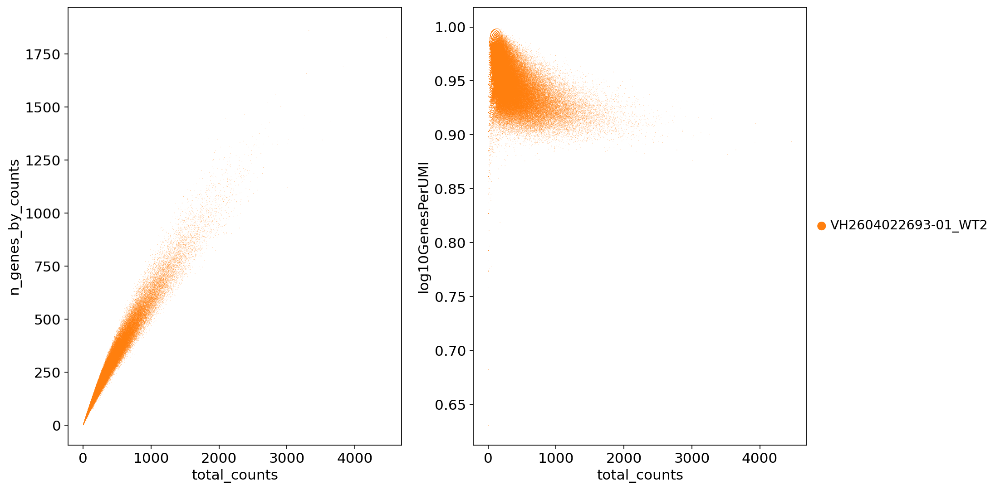

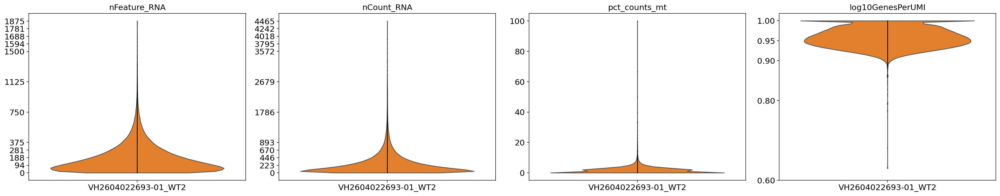

In [13]:
def data_qc(adata, out_dir):
    
    def calculate_breaks(x):
        x = np.array(x)
        xx = np.round(x)
        # Determine the steps based on the range
        if xx[1] < 100:
            scaled_times = np.ceil(100 / xx[1])
            steps = np.floor((scaled_times * xx[1] / 5) / 10) * 10 / scaled_times
        else:
            steps = np.floor(xx[1] / 5) / 10 * 10
            
        bk = np.arange(0, xx[1], steps)
        bk_minor = np.linspace(bk[0], bk[1], 5)
        bk = np.concatenate([bk_minor, bk[2:]])
        bk = bk[::-1]
        bk_minor = np.linspace(bk[0], bk[1], 5)
        bk = np.concatenate([bk_minor, bk[2:]])
        bk = bk[::-1]
        
        return [round(i,0) for i in bk]

    adata.var['mt'] = adata.var_names.str.upper().str.startswith('MT-') 
    adata.var['ribo'] = adata.var_names.str.upper().str.startswith(("RPS","RPL"))
    sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)
    adata.obs['log10GenesPerUMI'] = np.log10(adata.obs['n_genes_by_counts']) / np.log10(adata.obs['total_counts'])

    sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'log10GenesPerUMI'], groupby='sample', jitter=False, rotation=90, multi_panel=True, show=False)
    axes = plt.gcf().get_axes()
    size = plt.gcf().get_size_inches()
    axes[0].grid(False)
    axes[1].grid(False)
    axes[2].grid(False)
    axes[3].grid(False)
    plt.savefig(os.path.join(out_dir, 'orig_nCount_nFeature_voilon.png'), bbox_inches = 'tight', pad_inches = 0.1)

    fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(14, 7))
    sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts', color="sample", title="", legend_loc='none', ax=ax1, show=False)
    sc.pl.scatter(adata[adata.obs['log10GenesPerUMI']>0.6], x='total_counts', y='log10GenesPerUMI', title="", color="sample", ax=ax2, show=False)
    ax1.grid(False)
    ax2.grid(False)
    plt.tight_layout()
    fig.savefig(os.path.join(out_dir, 'orig_nCount_nFeature_scatter.png'), bbox_inches = 'tight')

    pd.DataFrame(adata.obs).to_csv(os.path.join(out_dir, 'all_cell_features_raw.xls'), sep='\t')

    for index, sample in enumerate(adata.obs['sample'].drop_duplicates()):
        out = os.path.join(out_dir, sample)
        os.makedirs(out, exist_ok=True)
        tmp = adata[adata.obs['sample']==sample]

        fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(14, 7))
        sc.pl.scatter(tmp, x='total_counts', y='n_genes_by_counts', color="sample", title="", legend_loc='none', ax=ax1, show=False)
        sc.pl.scatter(tmp[tmp.obs['log10GenesPerUMI']>0.6], x='total_counts', y='log10GenesPerUMI', color="sample", title="", ax=ax2, show=False)
        ax1.grid(False)
        ax2.grid(False)
        plt.tight_layout()
        fig.savefig(os.path.join(out, 'orig_nCount_nFeature_scatter.png'), bbox_inches = 'tight')

        fig, axs = plt.subplots(nrows=1, ncols=4, figsize=(size[0], size[1]))
        breaks1 = calculate_breaks([tmp.obs['n_genes_by_counts'].min(), tmp.obs['n_genes_by_counts'].max()])
        breaks2 = calculate_breaks([tmp.obs['total_counts'].min(), tmp.obs['total_counts'].max()])  
        sc.pl.violin(tmp, 'n_genes_by_counts', xlabel="", ylabel="", jitter=0, groupby='sample', ax=axs[0], show=False)
        sc.pl.violin(tmp, 'total_counts', xlabel="", ylabel="", jitter=0, groupby='sample', ax=axs[1], show=False)
        sc.pl.violin(tmp, 'pct_counts_mt', xlabel="", ylabel="", jitter=0, groupby='sample', ax=axs[2], show=False)
        sc.pl.violin(tmp[tmp.obs['log10GenesPerUMI']>0.6], 'log10GenesPerUMI', xlabel="", ylabel="", jitter=0, groupby='sample', ax=axs[3], show=False)
        axs[0].set_yticks(breaks1)
        axs[0].set_xlabel("")
        axs[0].set_title('nFeature_RNA')
        axs[1].set_yticks(breaks2)
        axs[1].set_xlabel("")
        axs[1].set_title('nCount_RNA')
        axs[2].set_xlabel("")
        axs[2].set_title("pct_counts_mt")
        axs[3].set_xlabel("")
        axs[3].set_title('log10GenesPerUMI')
        axs[3].set_yticks([0.6, 0.8, 0.9, 0.95, 1])
        axs[0].grid(False)
        axs[1].grid(False)
        axs[2].grid(False)
        axs[3].grid(False)

        plt.tight_layout()
        plt.savefig(os.path.join(out, 'orig_nCount_nFeature_voilon'))
        pd.DataFrame(tmp.obs).to_csv(os.path.join(out, 'all_cell_features_raw.xls'), sep='\t')
        
    return adata

## 质控
adata_qc = data_qc(adata, os.path.join(output_dir, 'report', '01-Data_QC'))
adata_qc.write(os.path.join(output_dir, 'data', 'adata_qc.h5ad'))

In [14]:
def filter_parameter_record(adata, output_file):
    dic = {}
    for index, sample in enumerate(adata.obs['sample'].drop_duplicates()):
        tmp = adata[adata.obs['sample']==sample]
        min_genes = int(np.quantile(tmp.obs['n_genes_by_counts'], 0.05))
        max_genes = int(np.quantile(tmp.obs['n_genes_by_counts'], 0.995))
        dic.setdefault('sample', []).append(sample)
        dic.setdefault('min_genes', []).append(15)
        dic.setdefault('max_genes', []).append(max_genes)
        dic.setdefault('min_pct_counts_mt', []).append(0)
        dic.setdefault('max_pct_counts_mt', []).append(10)
        dic.setdefault('min_GenesPerUMI', []).append(0.8)
        dic.setdefault('max_GenesPerUMI', []).append(0.99)

    pd.DataFrame(dic).to_csv(output_file, sep='\t', index=None)

adata_qc = sc.read_h5ad(os.path.join(output_dir, 'data', 'adata_qc.h5ad'))
filter_parameter_record(adata_qc, os.path.join(output_dir, 'filter_parameter.txt'))

In [15]:
adata_qc.obs['sample'].value_counts()

sample
VH2604022693-01_WT1    1117838
VH2604022693-01_WT2     252466
Name: count, dtype: int64

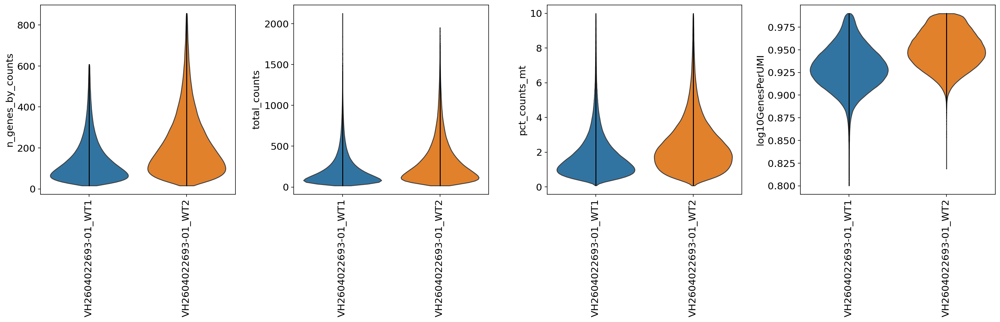

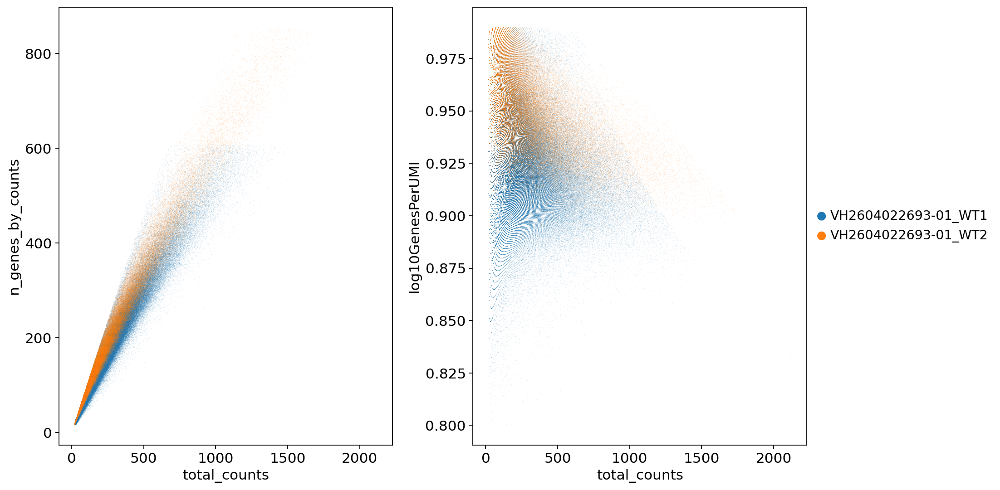

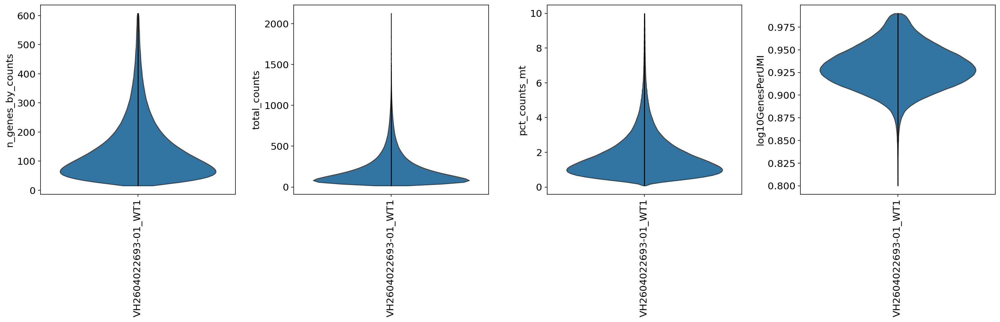

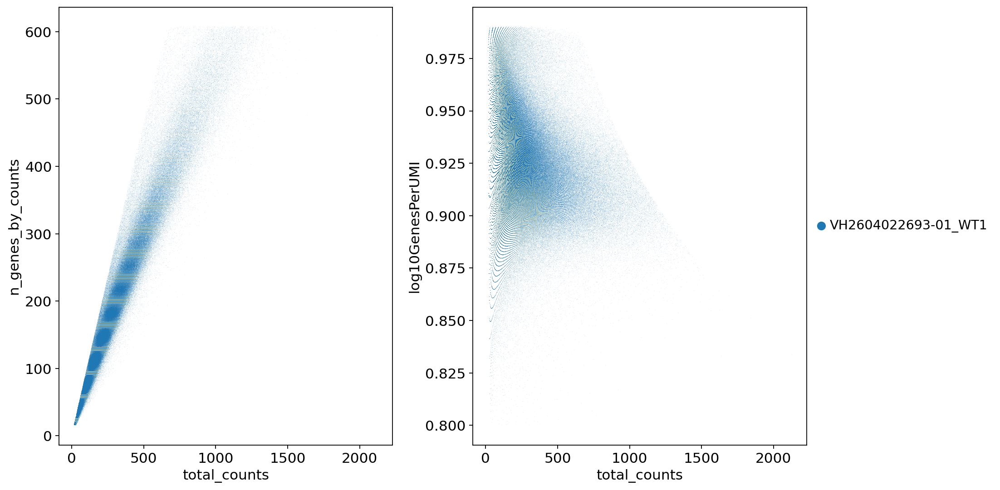

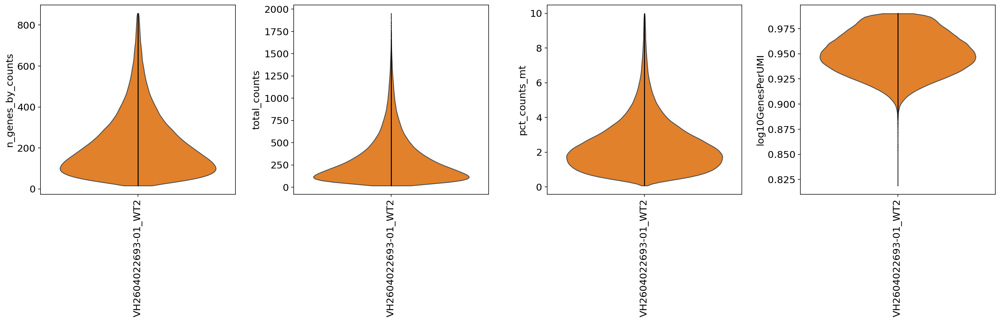

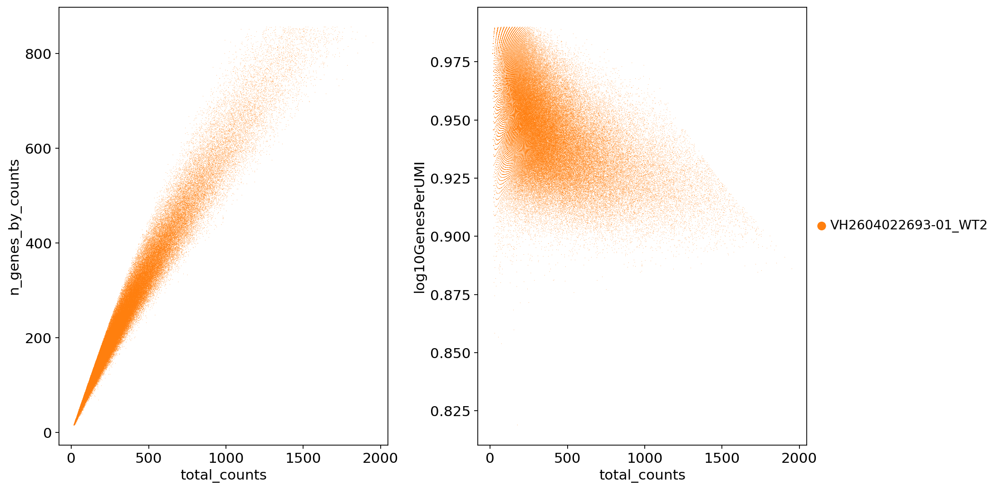

In [16]:
def cell_filter(adata_qc, para_file, out_dir):
    adata_list = []
    df_threshold = pd.read_csv(para_file, sep='\t')
    for index, row in df_threshold.iterrows():
        tmp = adata_qc[adata_qc.obs['sample']==row['sample']]
        tmp = tmp[
                    (tmp.obs['n_genes_by_counts'] > row['min_genes']) & \
                    (tmp.obs['n_genes_by_counts'] < row['max_genes']) & \
                    (tmp.obs['pct_counts_mt'] > row['min_pct_counts_mt']) & \
                    (tmp.obs['pct_counts_mt'] < row['max_pct_counts_mt']) & \
                    (tmp.obs['log10GenesPerUMI'] > row['min_GenesPerUMI']) & \
                    (tmp.obs['log10GenesPerUMI'] < row['max_GenesPerUMI'])
                 ]
        adata_list.append(tmp)
    adata = ad.concat(adata_list, join='inner', index_unique=None)
    adata.uns['spatial'] = adata_qc.uns['spatial']

    sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'log10GenesPerUMI'], groupby='sample', jitter=False, rotation=90, multi_panel=True, show=False)
    axes = plt.gcf().get_axes()
    size = plt.gcf().get_size_inches()
    axes[0].grid(False)
    axes[1].grid(False)
    axes[2].grid(False)
    axes[3].grid(False)
    plt.savefig(os.path.join(out_dir, 'filtered_nCount_nFeature_voilon.png'), bbox_inches = 'tight', pad_inches = 0.1)

    fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(14, 7))
    sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts', color="sample", title="", legend_loc='none', ax=ax1, show=False)
    sc.pl.scatter(adata[adata.obs['log10GenesPerUMI']>0.6], x='total_counts', y='log10GenesPerUMI', title="", color="sample", ax=ax2, show=False)
    ax1.grid(False)
    ax2.grid(False)
    plt.tight_layout()
    fig.savefig(os.path.join(out_dir, 'filtered_nCount_nFeature_scatter.png'), bbox_inches = 'tight')

    pd.DataFrame(adata.obs).to_csv(os.path.join(out_dir, 'all_cell_features_filter.xls'), sep='\t')

    for index, sample in enumerate(adata.obs['sample'].drop_duplicates()):
        out = os.path.join(out_dir, sample)
        os.makedirs(out, exist_ok=True)
        tmp = adata[adata.obs['sample']==sample]

        sc.pl.violin(tmp, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'log10GenesPerUMI'], groupby='sample', jitter=False, rotation=90, multi_panel=True, show=False)
        axes = plt.gcf().get_axes()
        axes[0].grid(False)
        axes[1].grid(False)
        axes[2].grid(False)
        axes[3].grid(False)
        plt.savefig(os.path.join(out, 'filtered_nCount_nFeature_voilon.png'), bbox_inches = 'tight', pad_inches = 0.1)

        fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(14, 7))
        sc.pl.scatter(tmp, x='total_counts', y='n_genes_by_counts', color="sample", title="", legend_loc='none', ax=ax1, show=False)
        sc.pl.scatter(tmp, x='total_counts', y='log10GenesPerUMI', color="sample", title="", ax=ax2, show=False)
        ax1.grid(False)
        ax2.grid(False)
        plt.tight_layout()
        fig.savefig(os.path.join(out, 'filtered_nCount_nFeature_scatter.png'), bbox_inches = 'tight')

    return adata

adata_qc = sc.read_h5ad(os.path.join(output_dir, 'data', 'adata_qc.h5ad'))
adata_filter = cell_filter(adata_qc, para_file=os.path.join(output_dir, 'filter_parameter.txt'), out_dir=os.path.join(output_dir, 'report', '02-Cell_filter'))
adata_filter.write(os.path.join(output_dir, 'data', 'adata_filtered.h5ad'))

In [17]:

def cluster_plot(adata, res, out_dir):
    with rc_context({'figure.figsize': (6, 6)}):
        sc.pl.umap(
            adata, 
            color=res,  
            title='Cell Cluster', 
            legend_loc='on data', 
            size=8,
            legend_fontsize=9, 
            legend_fontweight='normal', 
            legend_fontoutline=2,
            palette=palette,
            show=False
        )
        plt.savefig(os.path.join(out_dir, 'umap_dimplot_cluster.png'), facecolor='white', bbox_inches="tight", dpi=300)
        plt.savefig(os.path.join(out_dir, 'umap_dimplot_cluster.pdf'), facecolor='white', bbox_inches="tight")

    library_names = adata.obs['sample'].drop_duplicates().to_list()
    for library in library_names:
        with rc_context({'figure.figsize': (8, 8)}):
            sc.pl.spatial(
                adata[adata.obs['sample'] == library,:],
                color=[res],
                library_id=fov[library],
                title=f'{library}',
                size=1.0,
                alpha_img=0.3,
                palette=palette,
                show=False)
            plt.savefig(os.path.join(out_dir, f'spatial_{library}_cluster.png'), facecolor='white', bbox_inches="tight", dpi=300)
            plt.savefig(os.path.join(out_dir, f'spatial_{library}_cluster.pdf'), facecolor='white', bbox_inches="tight")
            
    groups = adata.obs['group'].drop_duplicates().tolist()
    if len(groups) > 1:
        axs = tuple(map(lambda x: f'ax{x+1}', range(len(groups))))
        fig, axs = plt.subplots(nrows=1, ncols=len(groups), figsize=(len(groups)*5, 5))
        for i in range(len(groups)):
            if i == len(groups) - 1:
                legend = 'right margin'
            else:
                legend = None
            sc.pl.umap(
                adata[adata.obs["group"]==groups[i]], 
                color=res, 
                title=groups[i], 
                ax=axs[i], 
                wspace=0.1, 
                size=8,
                legend_loc='on data', 
                legend_fontsize=12, 
                legend_fontweight='normal', 
                legend_fontoutline=2, 
                palette=palette,
                show=False
            )
        plt.savefig(os.path.join(out_dir, 'umap_split_group_cluster.png'), facecolor='white', bbox_inches="tight", dpi=300)
        plt.savefig(os.path.join(out_dir, 'umap_split_group_cluster.pdf'), facecolor='white', bbox_inches="tight")

    result = adata.obs.groupby([res, 'sample']).size().reset_index(name='number').pivot(index=res, columns='sample', values='number').reset_index()
    result.columns.name = None
    # result['Total'] = result.sum(axis=1)
    # result['Percent'] = round((result['Total'] / sum(result['Total'])) * 100, 1)
    result.to_csv(os.path.join(out_dir, 'cluster_statistics.xls'), sep='\t', index=None)
    adata.obs.to_csv(os.path.join(out_dir, 'all_cluster_cells_features.xls'), sep='\t')
    pd.DataFrame(adata.obsm['X_umap'], index=adata.obs_names, columns=['UMAP_1', 'UMAP_2']).to_csv(os.path.join(out_dir, 'data_umap.xls'), sep='\t')

    ct_by_sample=pd.crosstab(adata.obs['sample'], adata.obs[res])
    cts=ct_by_sample.div(ct_by_sample.sum(axis=1),axis=0)
    cls_dic=dict(zip(np.unique(adata.obs[res]), adata.uns[f'{res}_colors']))

    cts.plot(
        kind='bar',
        stacked=True,
        color=cts.columns.map(cls_dic),
        legend=False,
        figsize=(len(cts.index)*0.75, 4.5),
        width=0.98
    )
    plt.grid(False)
    plt.title('Cluster cell proportions')
    plt.legend(bbox_to_anchor=(1.02, 1), loc=2, borderaxespad=0, ncol=2)
    plt.savefig(os.path.join(out_dir, 'cluster_cell_proportion.png'), facecolor='white', bbox_inches="tight")
    plt.savefig(os.path.join(out_dir, 'cluster_cell_proportion.pdf'), facecolor='white', bbox_inches="tight")

    return adata


def marker_gene(adata, res, organism, out_dir):

    def go_enrichment(gene_list, organism, out_dir):
        if organism == 'Human':
            background = 'hsapiens_gene_ensembl'
        else:
            background = 'mmusculus_gene_ensembl'
            
        enr = gp.enrichr(
            gene_list=gene_list,
            gene_sets=['GO_Biological_Process_2023', 'GO_Cellular_Component_2023', 'GO_Molecular_Function_2023'],
            background=background,
            organism=organism, 
            cutoff=0.05,
            no_plot=True,
            outdir=out_dir,
            verbose=False
        )

        enr.results['Term'] = enr.results['Term'].str.replace(r' \(.*?\)', '', regex=True)
        enr.results['Gene_set'] = enr.results['Gene_set'].replace('GO_Biological_Process_2023', "BP").replace("GO_Cellular_Component_2023","CC").replace("GO_Molecular_Function_2023", "MF")
        enr.results.rename(columns={"Gene_set": "GO"}, inplace=True)
        
        gp.barplot(
            enr.results,
            column="Adjusted P-value",
            group='GO', # set group, so you could do a multi-sample/library comparsion
            size=10,
            top_term=5,
            figsize=(3,5),
            title="GO Enrichment",
            color=['darkgreen', 'darkblue', 'darkred'],
            ofname=os.path.join(out_dir, 'GO_Enrichment.png')
        )

    sc.tl.rank_genes_groups(
        adata, 
        groupby=res, 
        use_raw=True, 
        method="t-test", # method='t-test','wilcoxon',key_added='rank_genes_groups' 
        pts=True
    )
    
    sc.pl.rank_genes_groups_dotplot(
        adata, 
        groupby=res, 
        standard_scale="var", 
        n_genes=5,
        cmap='bwr',
        show=False,
    )
    plt.savefig(os.path.join(out_dir, 'dotplot_top5_marker_gene.png'), facecolor='white', bbox_inches="tight", dpi=200)

    result = adata.uns['rank_genes_groups']
    groups = result['names'].dtype.names
    all_diff = []
    for c in groups:
        out = os.path.join(out_dir, f'cluster{c}')
        os.makedirs(out, exist_ok=True)
        tmp = sc.get.rank_genes_groups_df(adata, group=c)
        tmp = tmp[(tmp['logfoldchanges']>0) & (tmp['pvals_adj']<0.05)]
        tmp.to_csv(os.path.join(out, 'differentially_expressed_genes.xls'), sep='\t', index=None)
        
        try:
            go_enrichment(tmp['names'], organism=organism, out_dir=out)
        except:
            print(tmp)

        tmp['cluster'] = c
        all_diff.append(tmp)

    all_diff = pd.concat(all_diff, axis=0)
    all_diff.rename(columns={'names': 'Symbol'}, inplace=True)
    all_diff.to_csv(os.path.join(out_dir, 'all_cluster_marker.xls'), sep='\t', index=None)
    all_diff['cluster'].value_counts().sort_index().to_csv(os.path.join(out_dir, 'cluster_diff_statistics.xls'), sep='\t')
    
    return adata


def celltype_anno(adata, res, anno_dict, out_dir):
    adata.obs['celltype'] = [anno_dict[clust] for clust in adata.obs[res]]    
    with rc_context({'figure.figsize': (6, 6)}):
        sc.pl.umap(
            adata, 
            color='celltype', 
            show=False, 
            title='Cell Types', 
            legend_loc='right margin', 
            legend_fontsize=9, 
            size=8, 
            palette = color_list,
            legend_fontweight='normal', 
            legend_fontoutline=2
        )
        plt.savefig(os.path.join(out_dir, 'umap_dimplot_celltype.png'), facecolor='white', bbox_inches="tight", dpi=300)

    groups = adata.obs['group'].drop_duplicates().tolist()
    if len(groups) > 1:
        axs = tuple(map(lambda x: f'ax{x+1}', range(len(groups))))
        fig, axs = plt.subplots(ncols=len(groups), figsize=(len(groups)*6, 6))
        for i in range(len(groups)):
            sc.pl.umap(
                adata[adata.obs["group"]==groups[i]],
                color="celltype", 
                title=groups[i], 
                ax=axs[i], 
                wspace=0.1, 
                size=10,
                legend_loc='on data', 
                legend_fontsize=12, 
                legend_fontweight='normal', 
                legend_fontoutline=2,
                palette = color_list,
                show=False
            )
        plt.savefig(os.path.join(out_dir, 'umap_dimplot_celltype_groups.png'), facecolor='white', bbox_inches="tight", dpi=300)

    pd.DataFrame(adata.obs).to_csv(os.path.join(out_dir, 'all_cell_features_celltype.xls'), sep='\t')

    library_names = adata.obs['sample'].drop_duplicates().to_list()
    for library in library_names:
        with rc_context({'figure.figsize': (8, 8)}):
            sc.pl.spatial(
                    adata[adata.obs['sample'] == library,:],
                    color=["celltype"],
                    library_id=fov[library],
                    title=f'{library}',
                    size=1.0,
                    alpha_img=0.3, 
                    palette = color_list,
                    show=False
                )
            plt.savefig(os.path.join(out_dir, f'spatial_{library}_celltype.png'), facecolor='white', bbox_inches="tight", dpi=300)
                
    ct_by_sample=pd.crosstab(adata.obs['sample'], adata.obs['celltype'])
    cts=ct_by_sample.div(ct_by_sample.sum(axis=1),axis=0)
    cls_dic=dict(zip(np.unique(adata.obs['celltype']), adata.uns['celltype_colors']))

    cts.plot(
        kind='bar',
        stacked=True,
        color=cts.columns.map(cls_dic),
        legend=False,
        figsize=(len(cts.index)*1.2, 4),
        width=0.98
    )
    plt.grid(False)
    plt.title('Cell type proportions')
    plt.legend(bbox_to_anchor=(1.02, 1), loc=2, borderaxespad=0)
    plt.savefig(os.path.join(out_dir, 'celltype_proportion.png'), facecolor='white', bbox_inches="tight", dpi=300)
    
    return adata


In [22]:
fov = {'VH2604022693-01_WT1':"VH2604022693-01_WT1",
       'VH2604022693-01_WT2':"VH2604022693-01_WT2"}

In [23]:
color_list = ["#E41A1C", "#377EB8", "#4DAF4A", "#984EA3", "#FF7F00", "#A65628", "#FFFF33", "#F781BF", "#999999", "#E5D8BD", "#B3CDE3", "#CCEBC5", "#FED9A6", "#FBB4AE", "#8DD3C7", "#BEBADA", "#80B1D3", "#B3DE69", "#FCCDE5", "#BC80BD", "#FFED6F", "#8DA0CB", "#E78AC3", "#E5C494", "#CCCCCC", "#FB9A99", "#E31A1C"]


        names      scores  logfoldchanges     pvals  pvals_adj  pct_nz_group  \
0      mt-Nd5  249.500916        3.252417  0.000000   0.000000      0.695356   
1     mt-Cytb  167.246979        1.866709  0.000000   0.000000      0.764845   
2          C3  153.093735        1.339238  0.000000   0.000000      0.908243   
3       Apoc3  152.173416        1.580556  0.000000   0.000000      0.825078   
4        Ass1  149.188263        1.822230  0.000000   0.000000      0.671260   
...       ...         ...             ...       ...        ...           ...   
9738    Fut10    2.164395        0.678651  0.030437   0.049132      0.000531   
9739     Tcf7    2.163591        0.331839  0.030499   0.049227      0.001842   
9740     Rgmb    2.161871        0.243071  0.030631   0.049435      0.003228   
9741    H2-Q4    2.161850        0.271984  0.030633   0.049435      0.002638   
9742    Ttbk1    2.158365        0.882314  0.030903   0.049862      0.000354   

      pct_nz_reference  
0             

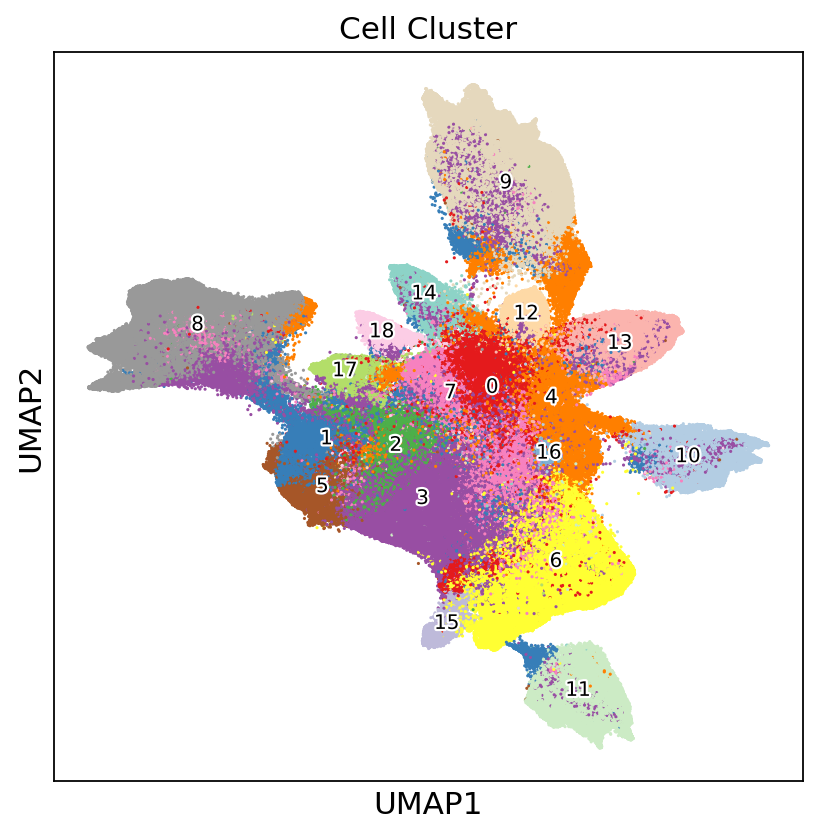

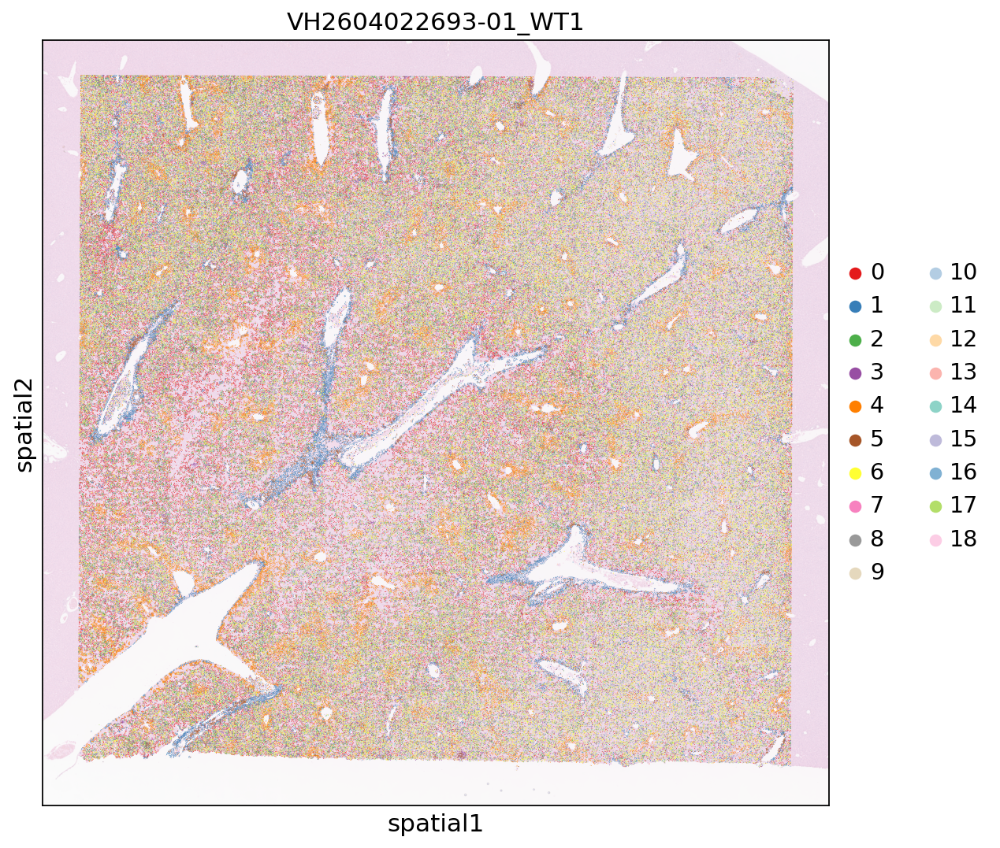

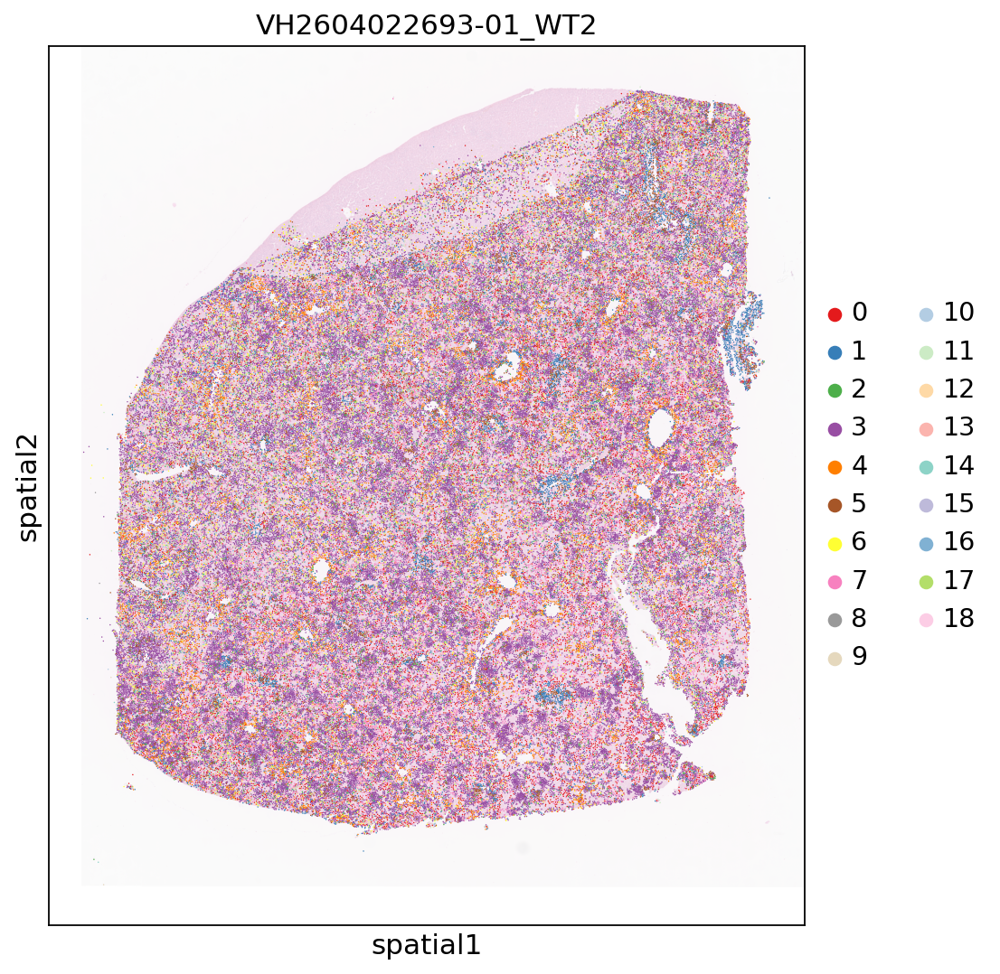

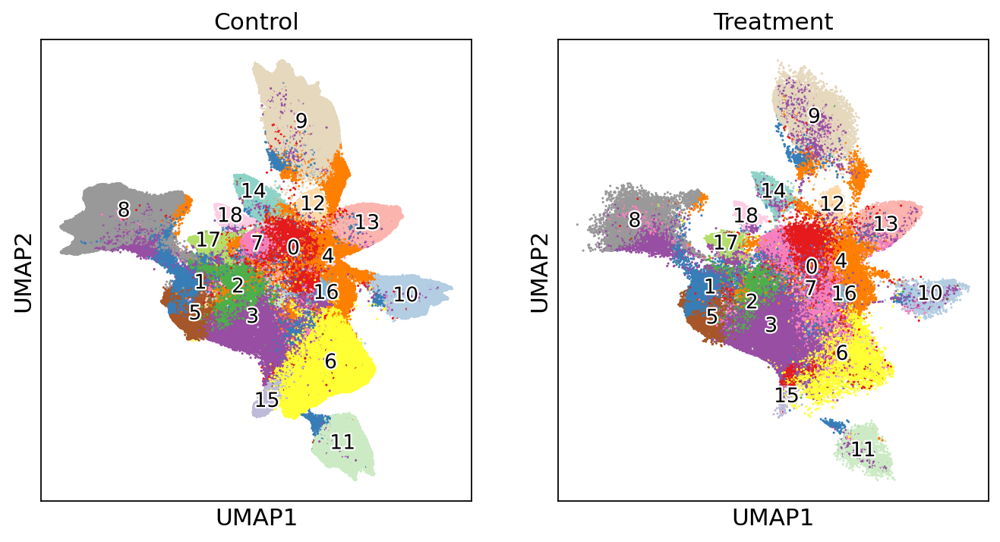

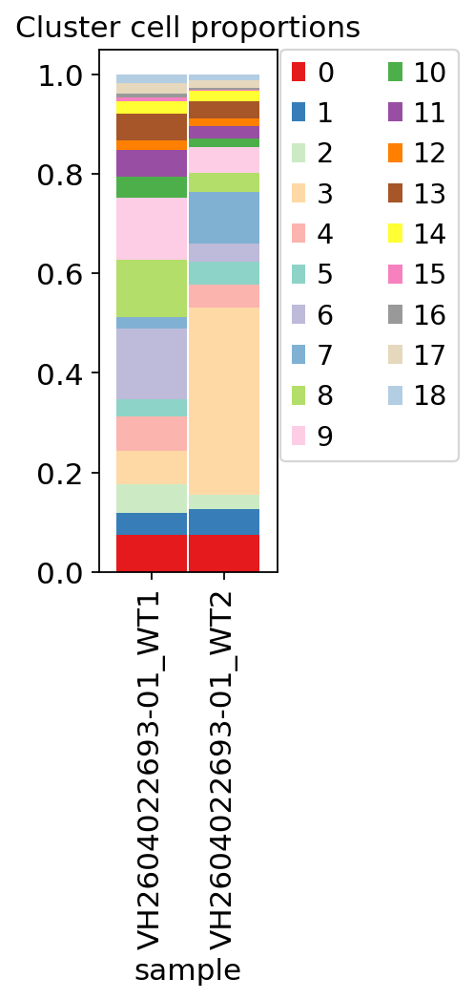

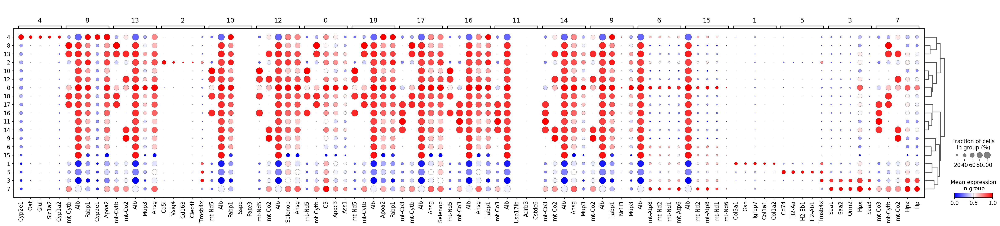

In [24]:
res = 'res_0.6'
adata = sc.read_h5ad(os.path.join(output_dir, 'data', 'adata_Cluster.h5ad'))
adata = cluster_plot(adata, res, out_dir=os.path.join(output_dir, 'report', '03-Dimension_reduction_cluster'))
adata = marker_gene(adata, res, organism='mouse', out_dir=os.path.join(output_dir, 'report', '04-Marker_gene_analysis'))

In [25]:
print(adata.obs.columns)

Index(['sample', 'group', 'location_id', 'region', 'cell_area',
       'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt',
       'log10GenesPerUMI', 'res_0.4', 'res_0.5', 'res_0.6'],
      dtype='object')


In [ ]:
major_annot = {
    "0": 'Periportal hepatocyte',
    "1": 'Hepatic stellate cell',
    "2": 'Hepatocyte', 
    "3": 'Inflammatory hepatocyte',
    "4": 'Pericentral hepatocyte', 
    "5": 'Kupffer cell',
    "6": 'Pericentral hepatocyte',
    "7": 'Inflammatory hepatocyte',
    "8": 'Pericentral hepatocyte',
    "9": 'Hepatocyte', 
    "10": 'Hepatocyte',
    "11": 'Hepatocyte', 
    "12": 'Periportal hepatocyte',
    "13": 'Periportal hepatocyte',
    "14": 'Periportal hepatocyte',
    "15": 'Tumor',
    "15": 'Tumor',
    "15": 'Tumor',
    "15": 'Tumor'
}

adata = celltype_anno(
    adata,
    res=res, 
    anno_dict=major_annot, 
    out_dir=os.path.join(output_dir, 'report', '05-Cell_type_annotation')
)

adata.write(os.path.join(output_dir, 'data', 'adata_celltype.h5ad'))